In [160]:
print("My first Data Science project!")
print("Name: Sundheep")
print("Goal: Analyze data and build a machine learning model")

My first Data Science project!
Name: Sundheep
Goal: Analyze data and build a machine learning model


In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Scikit-learn version: 1.9.1


In [162]:
df = pd.read_csv("C:/Users/HP/Desktop/Data-Scientist-Projects/Predictive-Maintenance/data/ai4i2020.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [163]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 0

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure 

In [164]:
failure_counts = df["Machine failure"].value_counts().sort_index()

print("Machine failure counts:")
print(failure_counts)

print("\nFailure percentage:")
print(
    (df["Machine failure"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

Machine failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


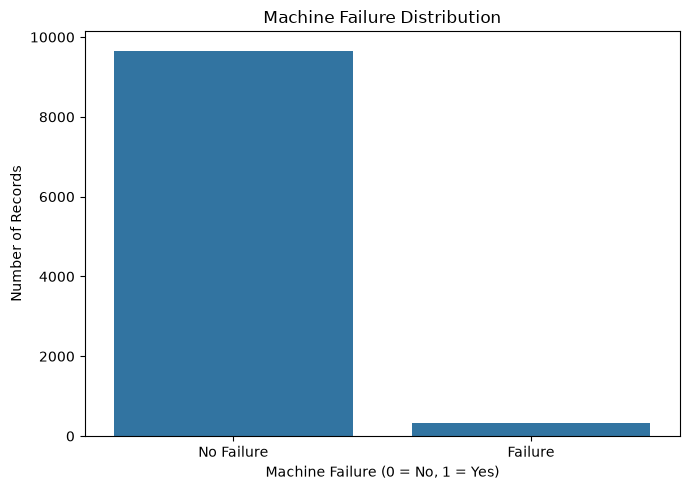

In [165]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Failure", "Failure"])

plt.tight_layout()
plt.show()

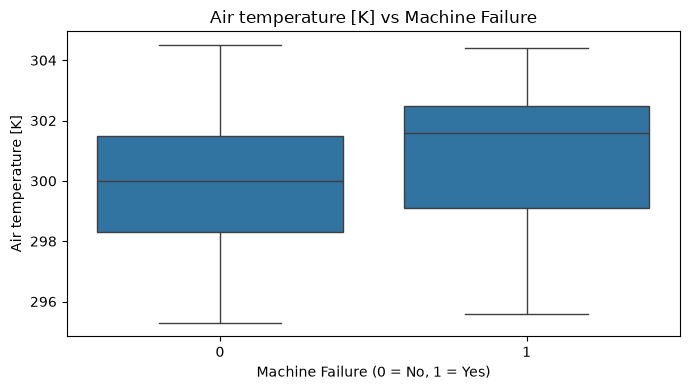

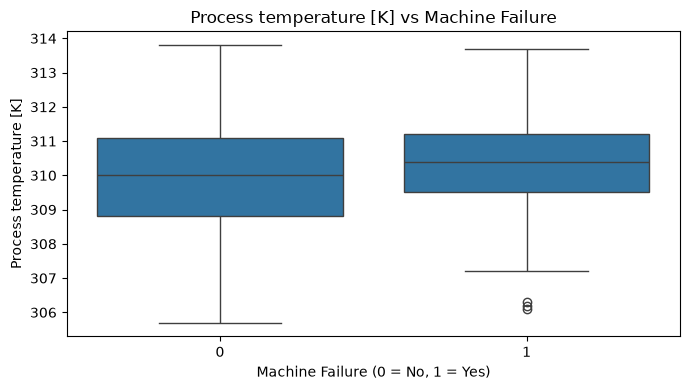

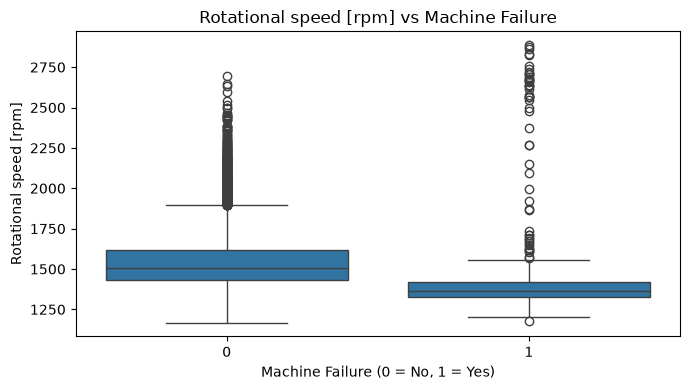

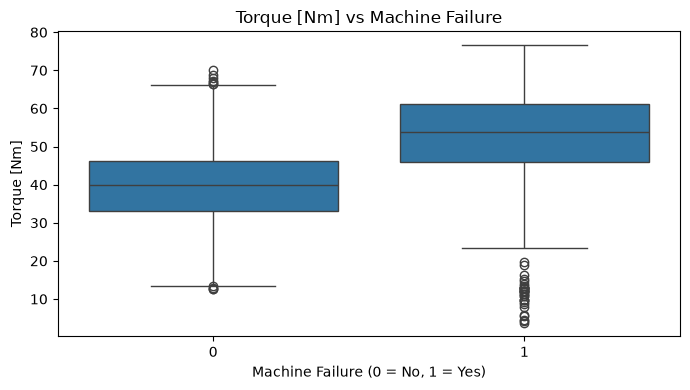

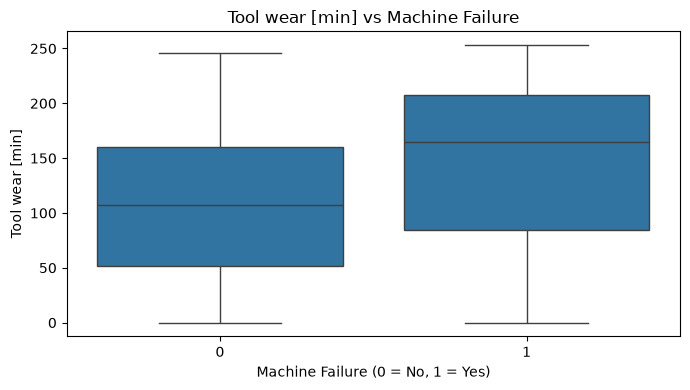

In [166]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for feature in features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

In [167]:
failure_comparison = (
    df.groupby("Machine failure")[features]
    .mean()
    .round(2)
    .T
)

failure_comparison.columns = [
    "No Failure",
    "Failure"
]

failure_comparison["Difference"] = (
    failure_comparison["Failure"]
    - failure_comparison["No Failure"]
)

failure_comparison

,No Failure,Failure,Difference
Air temperature [K],299.97,300.89,0.92
Process temperature [K],310.00,310.29,0.29
Rotational speed [rpm],1540.26,1496.49,-43.77
Torque [Nm],39.63,50.17,10.54
Tool wear [min],106.69,143.78,37.09


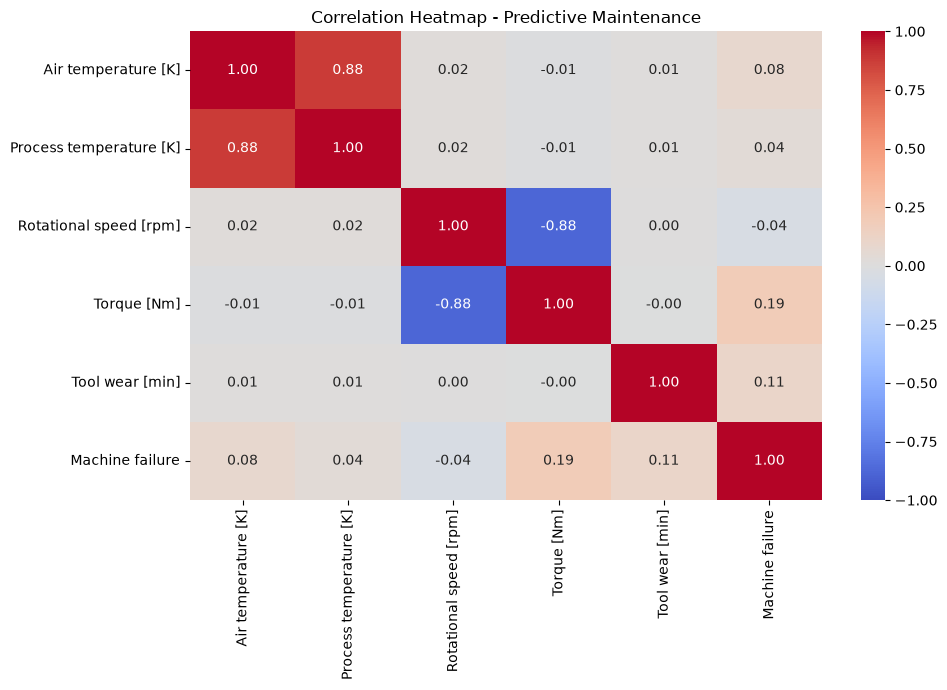

In [168]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Predictive Maintenance")
plt.tight_layout()
plt.show()

In [169]:
# Define sensor features and operating conditions
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df["Machine failure"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (10000, 6)
Target shape: (10000,)

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [170]:
print("Features used for prediction:")
print(X.columns.tolist())

print("\nTarget column:", y.name)

assert "Machine failure" not in X.columns
assert not any(
    col in X.columns
    for col in ["TWF", "HDF", "PWF", "OSF", "RNF"]
)

print("\nLeakage checks passed.")

Features used for prediction:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target column: Machine failure

Leakage checks passed.


In [171]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining failure rate:")
print(round(y_train.mean() * 100, 2), "%")

print("Testing failure rate:")
print(round(y_test.mean() * 100, 2), "%")

Training records: 8000
Testing records: 2000

Training failure rate:
3.39 %
Testing failure rate:
3.4 %


In [172]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Preprocessing and Logistic Regression pipeline created.")

Preprocessing and Logistic Regression pipeline created.


In [173]:
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [174]:
y_pred = model.predict(X_test)

print("Actual test labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred[:10].tolist())

Actual test labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Predicted labels:
[1, 1, 1, 0, 1, 1, 1, 0, 0, 1]


Accuracy: 0.8245
Precision: 0.1418
Recall: 0.8235
F1-score: 0.2419

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



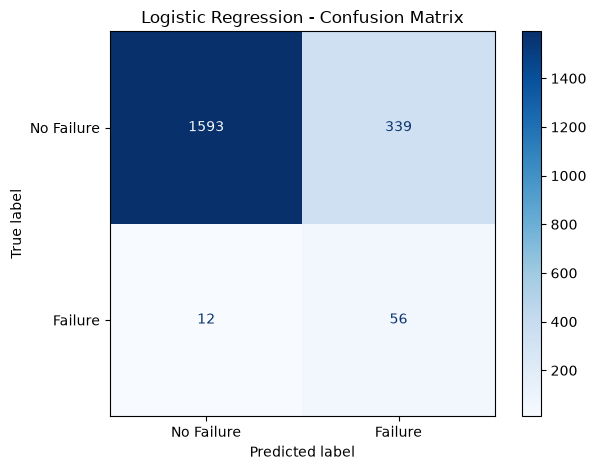

In [175]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.66      0.68        68

    accuracy                           0.98      2000
   macro avg       0.85      0.83      0.84      2000
weighted avg       0.98      0.98      0.98      2000

Average precision (PR-AUC summary): 0.7575


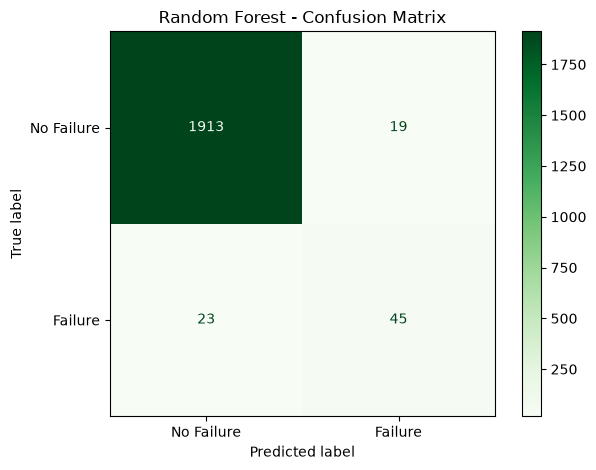

In [176]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    average_precision_score
)
import matplotlib.pyplot as plt

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

print(
    "Average precision (PR-AUC summary):",
    round(average_precision_score(y_test, rf_prob), 4)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [177]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    average_precision_score
)

# Create a validation split from the training set
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a temporary model for threshold selection
rf_tuning_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_tuning_model.fit(X_subtrain, y_subtrain)

# Estimate failure probabilities on validation data
val_prob = rf_tuning_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

# Select the best precision among thresholds achieving >= 80% recall
target_recall = 0.80
eligible = [
    i for i, threshold in enumerate(thresholds)
    if recall[i] >= target_recall
]

if eligible:
    best_idx = max(eligible, key=lambda i: precision[i])
    selected_threshold = thresholds[best_idx]

    print("Selected threshold:", round(selected_threshold, 4))
    print("Validation precision:", round(precision[best_idx], 4))
    print("Validation recall:", round(recall[best_idx], 4))
else:
    selected_threshold = None
    print("No threshold achieved the target recall.")

Selected threshold: 0.2567
Validation precision: 0.4037
Validation recall: 0.8148


Selected threshold: 0.2567

Test classification report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1932
           1       0.46      0.85      0.59        68

    accuracy                           0.96      2000
   macro avg       0.73      0.91      0.79      2000
weighted avg       0.98      0.96      0.97      2000

Test average precision: 0.7575


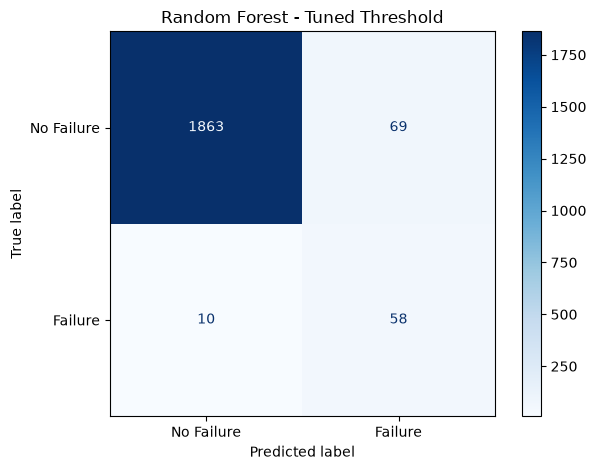

In [178]:
if selected_threshold is not None:
    # Retrain using the full training set
    rf_model.fit(X_train, y_train)

    # Evaluate on the untouched test set
    test_prob = rf_model.predict_proba(X_test)[:, 1]

    threshold_pred = (
        test_prob >= selected_threshold
    ).astype(int)

    print("Selected threshold:", round(selected_threshold, 4))
    print("\nTest classification report:")
    print(classification_report(
        y_test,
        threshold_pred,
        zero_division=0
    ))

    print(
        "Test average precision:",
        round(average_precision_score(y_test, test_prob), 4)
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        threshold_pred,
        display_labels=["No Failure", "Failure"],
        cmap="Blues"
    )

    plt.title("Random Forest - Tuned Threshold")
    plt.tight_layout()
    plt.show()

                              Feature  Importance
6              numerical__Torque [Nm]    0.307202
5   numerical__Rotational speed [rpm]    0.296446
7          numerical__Tool wear [min]    0.207833
3      numerical__Air temperature [K]    0.101792
4  numerical__Process temperature [K]    0.069011
1                 categorical__Type_L    0.009026
2                 categorical__Type_M    0.005620
0                 categorical__Type_H    0.003071


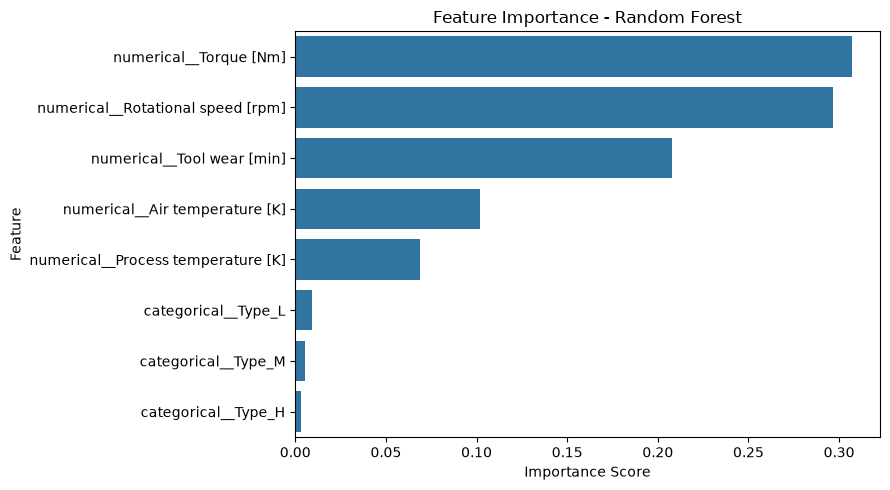

In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature names after preprocessing
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract Random Forest feature importance scores
importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [181]:
import os
import joblib

os.makedirs("C:/Users/HP/Desktop/Data-Scientist-Projects/Predictive-Maintenance/models", exist_ok=True)

joblib.dump(
    rf_model,
    "C:/Users/HP/Desktop/Data-Scientist-Projects/Predictive-Maintenance/models/random_forest_model.joblib"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [182]:
import os

print("Current working directory:", os.getcwd())

Current working directory: C:\Users\HP\Desktop\Data-Scientist-Projects\Predictive-Maintenance


In [183]:
import os

print("Dataset exists:", os.path.exists("data/ai4i2020.csv"))
print(
    "Model exists:",
    os.path.exists("models/random_forest_model.joblib")
)

Dataset exists: True
Model exists: True
